# 3. Assignment Machine Learning for Classification



In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
data = 'wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [3]:
!wget $data -O course_lead_scoring_2026.csv

--2026-10-22 18:45:53--  http://wget/
Resolving wget (wget)... failed: Name or service not known.
wget: unable to resolve host address ‘wget’
--2026-10-22 18:45:53--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.003s  

2026-10-22 18:45:53 (97.7 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]

FINISHED --2026-10-22 18:45:53--
Total wall clock time: 0.1s
Downloaded: 1 files, 272K in 0.003s (97.7 MB/s)


In [4]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
df.head().T

,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,NaN,north_america
annual_income,88160.0,72688.0,44697.0,NaN,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


In [6]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [7]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [8]:
df.nunique()

lead_source                    5
industry                       6
employment_status              4
location                       5
annual_income               4313
number_of_courses_viewed       7
interaction_count             14
lead_score                    99
converted                      2
dtype: int64

In [9]:
df.industry.value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
Name: count, dtype: int64

In [10]:
categorical = ['lead_source','industry','employment_status','location','converted']
numerical = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']

In [11]:
df[categorical] = df[categorical].fillna('NA')

In [12]:
df[numerical] = df[numerical].fillna(0)

In [13]:
df.head().T

,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,NA,north_america
annual_income,88160.0,72688.0,44697.0,0.0,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


In [14]:
df.industry.value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

In [15]:
df[numerical].corr()

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000


## Setting up the validation framework

* Perform the train/validation/test split with Scikit-Learn

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [18]:
len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [19]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [20]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [21]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

## EDA

* Check missing values
* Look at the target variable (Converted)
* Look at numerical and categorical variables

In [22]:
df_full_train = df_full_train.reset_index(drop=True)

In [23]:
df_full_train.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [24]:
df_full_train.converted.value_counts(normalize= True)

converted
1    0.57875
0    0.42125
Name: proportion, dtype: float64

In [25]:
df_full_train.converted.mean()

np.float64(0.57875)

In [26]:
df_full_train[categorical].nunique()

lead_source          6
industry             7
employment_status    5
location             6
converted            2
dtype: int64

In [27]:
df_full_train.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,paid_ads,technology,student,europe,38757.0,0,0,0.15,0
1,paid_ads,healthcare,self_employed,north_america,56516.0,2,6,0.59,1
2,paid_ads,retail,employed,NA,54963.0,1,0,0.13,0
3,social_media,retail,self_employed,NA,26237.0,1,5,0.46,0
4,organic_search,retail,student,north_america,21992.0,3,6,0.70,1


## Feature importance: Mutual information

Mutual information 

In [28]:
from sklearn.metrics import mutual_info_score

In [29]:
category = ['lead_source','industry','employment_status','location']

In [30]:
def mutual_info_churn_score(series):
    return round(mutual_info_score(series, y_train),2)

In [31]:
mi = df_train[category].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

## One-hot encoding

* Use Scikit-Learn to encode categorical features

In [32]:
from sklearn.feature_extraction import DictVectorizer

In [33]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[category + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[category + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

## Training logistic regression with Scikit-Learn

* Train a model with Scikit-Learn
* Apply it to the validation dataset
* Calculate the accuracy

In [34]:
from sklearn.linear_model import LogisticRegression

In [35]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [36]:
model.intercept_[0]

np.float64(-0.09288149430630052)

In [37]:
model.coef_[0].round(3)

array([-0.   , -0.001,  0.033, -0.023, -0.055, -0.047, -0.004, -0.025,
       -0.012, -0.024, -0.009, -0.032,  0.012,  0.252,  0.019, -0.002,
       -0.041,  0.013, -0.065,  0.027, -0.025, -0.005, -0.02 , -0.015,
       -0.01 , -0.022, -0.021,  0.105])

In [38]:
y_pred = model.predict_proba(X_val)[:, 1]
y_pred

array([0.54472295, 0.79005191, 0.50977882, 0.52913934, 0.82072017,
       0.54245972, 0.50178712, 0.54698383, 0.82553291, 0.40583727,
       0.91301561, 0.33581811, 0.3078986 , 0.42704772, 0.62192275,
       0.53665458, 0.41931913, 0.84087339, 0.79969125, 0.61790114,
       0.61625177, 0.68059912, 0.85605897, 0.80784865, 0.62045997,
       0.45970701, 0.54556694, 0.41221371, 0.72714005, 0.46812072,
       0.77222173, 0.79043872, 0.61433884, 0.78549743, 0.49753403,
       0.66077266, 0.69804748, 0.7689654 , 0.65657485, 0.64127885,
       0.66509096, 0.57942799, 0.67830929, 0.61186087, 0.86890227,
       0.41469665, 0.84130122, 0.74229349, 0.68028533, 0.71891426,
       0.86417924, 0.64043347, 0.54246978, 0.70225148, 0.27894882,
       0.70826471, 0.62310687, 0.47781739, 0.37914002, 0.69936026,
       0.52032849, 0.69977687, 0.75148933, 0.58087478, 0.47001782,
       0.56863462, 0.91297177, 0.79972016, 0.82206537, 0.36140182,
       0.66132377, 0.52330037, 0.79295454, 0.72068061, 0.71234

In [39]:
decision = (y_pred >= 0.5)

In [40]:
(y_val == decision).mean()

np.float64(0.651)

In [41]:
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = decision.astype(int)
df_pred['actual'] = y_val

In [42]:
df_pred['correct'] = df_pred.prediction == df_pred.actual

In [43]:
df_pred.correct.mean()

np.float64(0.651)

In [44]:
decision.astype(int)

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0,

In [45]:
df_pred

,probability,prediction,actual,correct
0,0.544723,1,0,False
1,0.790052,1,1,True
2,0.509779,1,1,True
3,0.529139,1,1,True
4,0.820720,1,0,False
...,...,...,...,...
995,0.741848,1,1,True
996,0.657033,1,1,True
997,0.757786,1,1,True
998,0.779014,1,1,True


In [46]:
from sklearn.metrics import accuracy_score

In [47]:
accuracy_score(decision, y_val)

0.651

In [48]:
# For lead source

features = [
    'industry',
    'employment_status',
    'location',
    'annual_income',
    'number_of_courses_viewed',
    'interaction_count',
    'lead_score' ]

train_dict = df_train[features].to_dict(orient='records')
X_t1 = dv.fit_transform(train_dict)

val_dict = df_val[features].to_dict(orient='records')
X_v1 = dv.transform(val_dict)

m1 = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

m1.fit(X_t1, y_train)
d1 = (m1.predict_proba(X_v1)[:, 1]) >= 0.5

print('Accuracy: ' + str(accuracy_score(d1, y_val)) + 
      ' Difference: ' + str((accuracy_score(decision, y_val) - accuracy_score(d1, y_val))))

Accuracy: 0.648 Difference: 0.0030000000000000027


In [49]:
# For no of courses viewed

f2 = [
    'industry',
    'employment_status',
    'location',
    'annual_income',
    'lead_source',
    'interaction_count',
    'lead_score' ]

train_dict = df_train[f2].to_dict(orient='records')
X_t2 = dv.fit_transform(train_dict)

val_dict = df_val[f2].to_dict(orient='records')
X_v2 = dv.transform(val_dict)

m2 = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

m2.fit(X_t2, y_train)
d2 = (m2.predict_proba(X_v2)[:, 1]) >= 0.5

print('Accuracy: ' + str(accuracy_score(d2, y_val)) + 
      ' Difference: ' + str((accuracy_score(decision, y_val) - accuracy_score(d2, y_val))))

Accuracy: 0.645 Difference: 0.006000000000000005


In [50]:
# For interaction count

f3 = [
    'industry',
    'employment_status',
    'location',
    'annual_income',
    'number_of_courses_viewed',
    'lead_source',
    'lead_score']

train_dict = df_train[f3].to_dict(orient='records')
X_t3 = dv.fit_transform(train_dict)

val_dict = df_val[f3].to_dict(orient='records')
X_v3 = dv.transform(val_dict)

m3 = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

m3.fit(X_t3, y_train)
d3 = (m3.predict_proba(X_v3)[:, 1]) >= 0.5

print('Accuracy: ' + str(accuracy_score(d3, y_val)) + 
      ' Difference: ' + str((accuracy_score(decision, y_val) - accuracy_score(d3, y_val))))

Accuracy: 0.593 Difference: 0.05800000000000005


In [51]:
ls =[(accuracy_score(decision, y_val) - accuracy_score(d1, y_val)),
     (accuracy_score(decision, y_val) - accuracy_score(d2, y_val)),
     (accuracy_score(decision, y_val) - accuracy_score(d3, y_val))]

In [52]:
min(ls)

0.0030000000000000027

In [53]:
# Regularized LR

In [54]:

from sklearn.model_selection import GridSearchCV

param_grid = {'C': [0.000001, 0.00001, 0.0001, 0.001]}

log_reg = LogisticRegression(l1_ratio=0, solver='liblinear', max_iter=1500, random_state=42)

grid_search = GridSearchCV(log_reg, param_grid, cv=55, scoring='accuracy')
grid_search.fit(X_train, y_train)

results_df = pd.DataFrame(grid_search.cv_results_)

summary_df = results_df[['param_C', 'mean_test_score']]

summary_df.columns = ['C Parameter', 'Mean Accuracy']
print(summary_df.to_string(index=False))


 C Parameter  Mean Accuracy
    0.000001       0.579320
    0.000010       0.579320
    0.000100       0.579320
    0.001000       0.656333


In [55]:
## ROC AUC Curve

In [56]:
from sklearn.metrics import roc_auc_score, auc, roc_curve

In [57]:
roc_auc_score(y_train,df_train['lead_score'])

0.7882254810906102

In [58]:
roc_auc_score(y_train,df_train['number_of_courses_viewed'])

0.7229894623989618

In [59]:
roc_auc_score(y_train,df_train['interaction_count'])

0.7649203047563227

In [60]:
roc_auc_score(y_train,df_train['annual_income'])

0.6081977776250831

In [61]:
roc_auc_score(y_val, decision)

0.5979992085868329

In [62]:
scores = []

thresholds = np.linspace(0.0, 1.0, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    Recall = tp / (tp + fn)  if (tp + fn) > 0 else np.nan
    Precision = tp / (fp + tp) if (tp + fp) > 0 else np.nan
    Diff = abs(Recall - Precision)
    F1 = 2*((Precision*Recall)/(Precision+Recall))
    scores.append((t, Recall, Precision, Diff, F1))
    
columns = ['Threshold', 'Recall', 'Precision', 'Difference', 'F1']
df_scores = pd.DataFrame(scores, columns=columns)
print(df_scores.head(-3).T)
    

                  0         1         2         3         4         5   \
Threshold   0.000000  0.010000  0.020000  0.030000  0.040000  0.050000   
Recall      1.000000  1.000000  1.000000  1.000000  1.000000  1.000000   
Precision   0.586000  0.586000  0.586000  0.586000  0.586000  0.586000   
Difference  0.414000  0.414000  0.414000  0.414000  0.414000  0.414000   
F1          0.738966  0.738966  0.738966  0.738966  0.738966  0.738966   

                  6         7         8         9   ...        88        89  \
Threshold   0.060000  0.070000  0.080000  0.090000  ...  0.880000  0.890000   
Recall      1.000000  1.000000  1.000000  1.000000  ...  0.054608  0.046075   
Precision   0.586000  0.586000  0.586000  0.586000  ...  0.914286  0.931034   
Difference  0.414000  0.414000  0.414000  0.414000  ...  0.859678  0.884959   
F1          0.738966  0.738966  0.738966  0.738966  ...  0.103060  0.087805   

                  90        91        92        93        94        95  \
Thresh

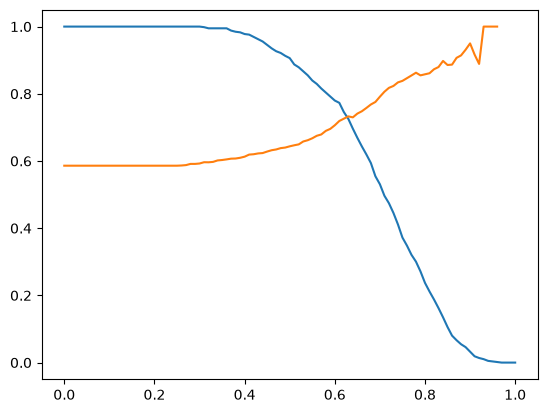

In [63]:
plt.plot(df_scores['Threshold'], df_scores['Recall'], label='Recall')
plt.plot(df_scores['Threshold'], df_scores['Precision'], label='Precision')
plt.show()

In [64]:
best_threshold = df_scores.loc[
    ~((df_scores['Precision'] == 0) & (df_scores['Recall'] == 0))
].sort_values('Difference').iloc[0]['Threshold']

print(best_threshold)

0.63


In [65]:
best_threshold1 = df_scores.loc[df_scores['Difference'].idxmin()]
round(best_threshold1,3)

Threshold     0.630
Recall        0.725
Precision     0.733
Difference    0.008
F1            0.729
Name: 63, dtype: float64

In [66]:
F1_threshold1 = df_scores.loc[df_scores['F1'].idxmax()]
round(F1_threshold1,3)

Threshold     0.410
Recall        0.976
Precision     0.619
Difference    0.357
F1            0.758
Name: 41, dtype: float64

In [67]:
!pip install tqdm
from tqdm.auto import tqdm
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

def train(df_train, y_train, C=1.0):
    dicts = df_train[category + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    return dv, model

def predict(df, dv, model):
    dicts = df[category + numerical].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [68]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx] 
    df_val = df_full_train.iloc[val_idx]
    y_train = df_full_train.converted[train_idx]
    y_val = df_full_train.converted[val_idx]

    dv, model = train(df_train, y_train, C=1.0)
    y_pred = predict(df_val, dv, model)
    scores.append(roc_auc_score(y_val, y_pred))

print(f"Mean: {np.mean(scores):.3f}, Std: {np.std(scores):.3f}")

Mean: 0.732, Std: 0.007


In [69]:
n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx] 
        df_val = df_full_train.iloc[val_idx]
        y_train = df_full_train.converted[train_idx]
        y_val = df_full_train.converted[val_idx]

        dv, model = train(df_train, y_train, C= C)
        y_pred = predict(df_val, dv, model)
        scores.append(roc_auc_score(y_val, y_pred))

    tqdm.write('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
